In [ ]:
!pip install -q kagglehub torch torchvision matplotlib seaborn pandas scikit-learn pillow

In [ ]:
import os
import torch
import kagglehub
import random
import matplotlib.pyplot as plt
import pandas as pd

from pathlib import Path
from PIL import Image
from collections import Counter

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("PyTorch Version:", torch.__version__)
print("GPU Available:", torch.cuda.is_available())

Device: cuda
PyTorch Version: 2.14.1+cu130
GPU Available: True


In [ ]:
dataset_path = kagglehub.dataset_download(
    "sumn2u/garbage-classification-v2"
)

dataset_path = Path(dataset_path)

print("Dataset downloaded successfully!")
print("Dataset Location:", dataset_path)

Using Colab cache for faster access to the 'garbage-classification-v2' dataset.
Dataset downloaded successfully!
Dataset Location: /kaggle/input/garbage-classification-v2


In [ ]:
for root, dirs, files in os.walk(dataset_path):
    level = len(Path(root).relative_to(dataset_path).parts)

    if level > 2:
        continue

    indent = "    " * level

    print(indent + os.path.basename(root) + "/")

    for file in files[:5]:
        print(indent + "    " + file)

    if len(files) > 5:
        print(indent + "    ...")

garbage-classification-v2/
    standardized_384/
        metal/
            metal_670.jpg
            metal_408.jpg
            metal_222.jpg
            metal_200.jpg
            metal_533.jpg
            ...
        glass/
            glass_438.jpg
            glass_773.jpg
            glass_996.jpg
            glass_473.jpg
            glass_1689.jpg
            ...
        biological/
            biological_211.jpg
            biological_392.jpg
            biological_524.jpg
            biological_515.jpg
            biological_450.jpg
            ...
        paper/
            paper_1307.jpg
            paper_686.jpg
            paper_1010.jpg
            paper_1284.jpg
            paper_854.jpg
            ...
        battery/
            battery_734.jpg
            battery_587.jpg
            battery_328.jpg
            battery_471.jpg
            battery_737.jpg
            ...
        trash/
            trash_338.jpg
            trash_151.jpg
            trash_167.jpg
       

In [ ]:
image_extensions = {".jpg", ".jpeg", ".png", ".webp"}

image_files = [
    file for file in dataset_path.rglob("*")
    if file.suffix.lower() in image_extensions
]

print("Total Images:", len(image_files))

print("\nSample Image Paths:")

for image in image_files[:10]:
    print(image)

Total Images: 36777

Sample Image Paths:
/kaggle/input/garbage-classification-v2/standardized_256/metal/metal_670.jpg
/kaggle/input/garbage-classification-v2/standardized_256/metal/metal_408.jpg
/kaggle/input/garbage-classification-v2/standardized_256/metal/metal_222.jpg
/kaggle/input/garbage-classification-v2/standardized_256/metal/metal_200.jpg
/kaggle/input/garbage-classification-v2/standardized_256/metal/metal_533.jpg
/kaggle/input/garbage-classification-v2/standardized_256/metal/metal_7.jpg
/kaggle/input/garbage-classification-v2/standardized_256/metal/metal_285.jpg
/kaggle/input/garbage-classification-v2/standardized_256/metal/metal_210.jpg
/kaggle/input/garbage-classification-v2/standardized_256/metal/metal_243.jpg
/kaggle/input/garbage-classification-v2/standardized_256/metal/metal_590.jpg


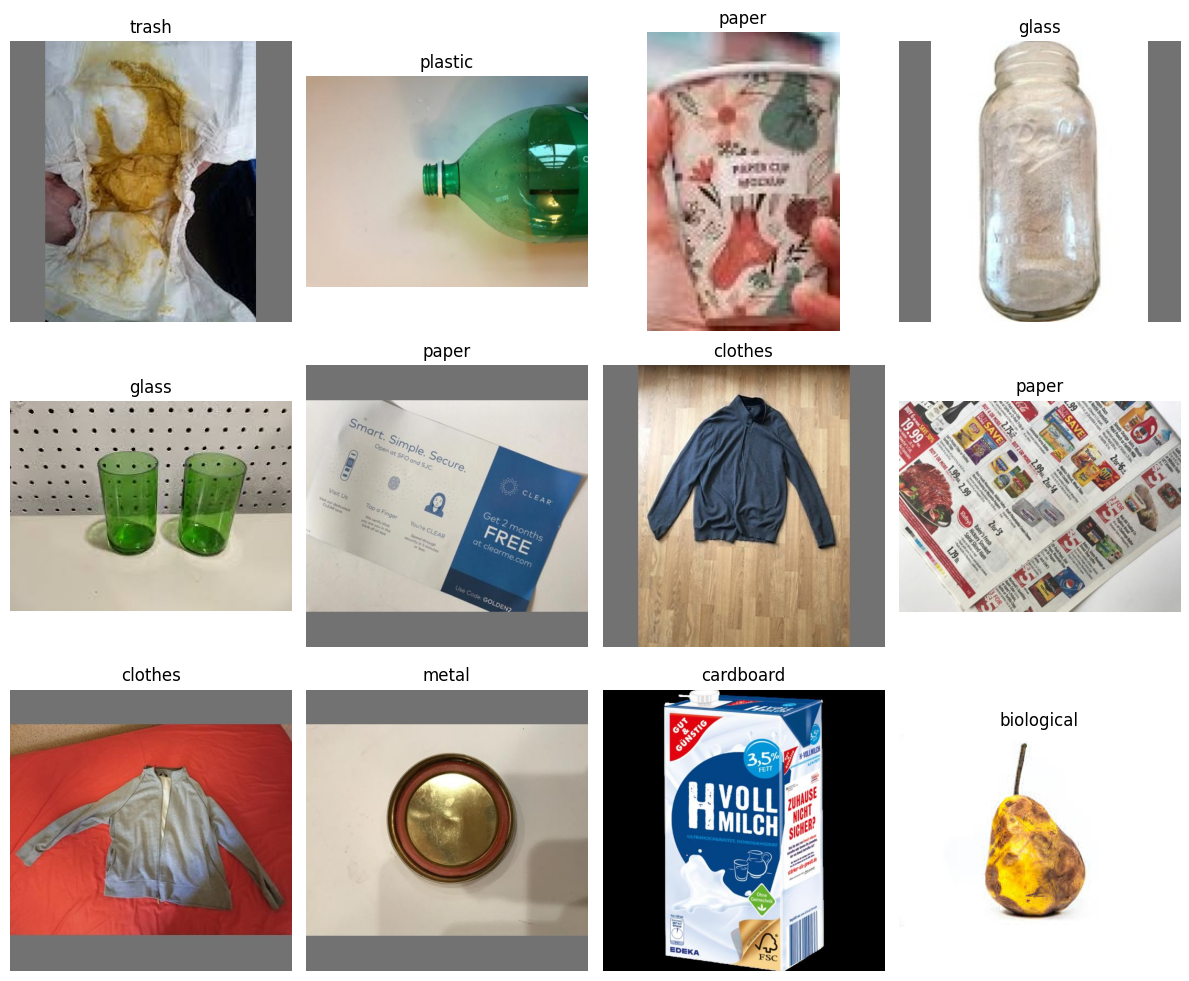

In [ ]:
sample_images = random.sample(
    image_files,
    min(12, len(image_files))
)

plt.figure(figsize=(12, 10))

for i, image_path in enumerate(sample_images):
    img = Image.open(image_path).convert("RGB")

    plt.subplot(3, 4, i + 1)
    plt.imshow(img)
    plt.title(image_path.parent.name)
    plt.axis("off")

plt.tight_layout()
plt.show()

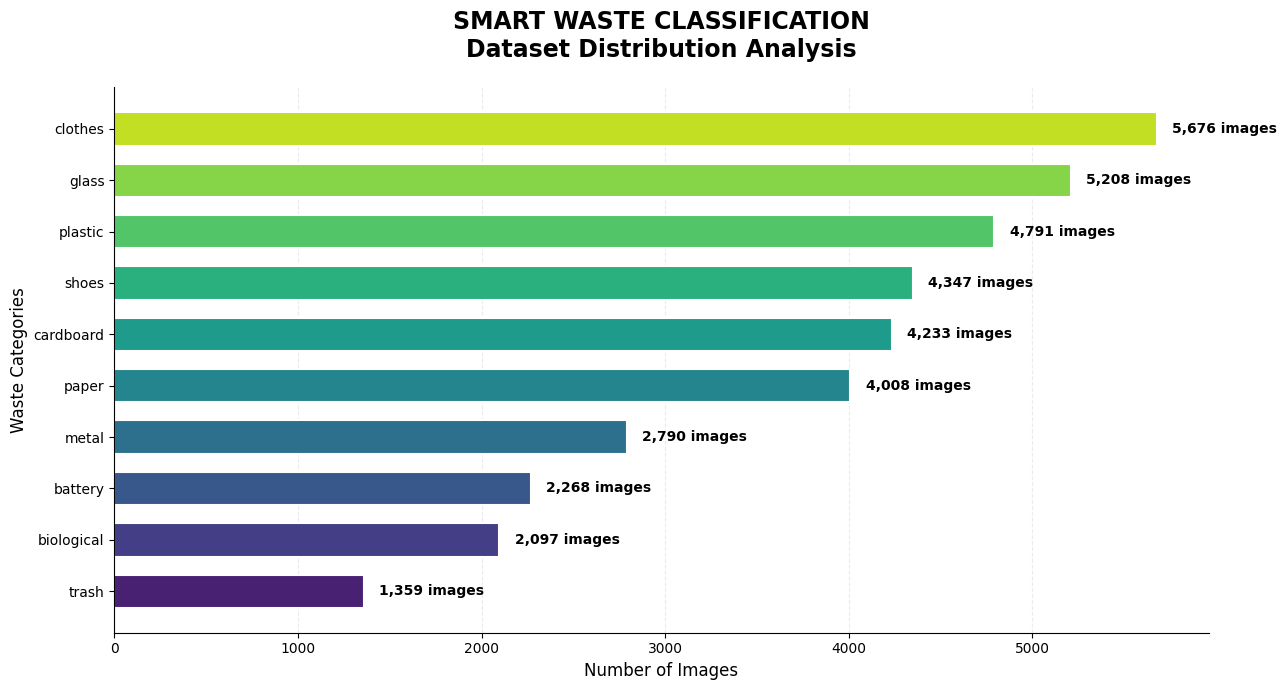

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

class_counts = Counter(
    image.parent.name for image in image_files
)

class_df = pd.DataFrame(
    class_counts.items(),
    columns=["Waste Category", "Number of Images"]
).sort_values(by="Number of Images", ascending=True)

plt.figure(figsize=(13, 7))

colors = sns.color_palette("viridis", len(class_df))

bars = plt.barh(
    class_df["Waste Category"],
    class_df["Number of Images"],
    color=colors,
    height=0.65,
    edgecolor="white",
    linewidth=1.5
)

for bar in bars:
    width = bar.get_width()
    plt.text(
        width + max(class_df["Number of Images"]) * 0.015,
        bar.get_y() + bar.get_height()/2,
        f'{int(width):,} images',
        va='center',
        fontsize=10,
        fontweight='bold'
    )

plt.title(
    "SMART WASTE CLASSIFICATION\nDataset Distribution Analysis",
    fontsize=17,
    fontweight="bold",
    pad=22
)

plt.xlabel("Number of Images", fontsize=12)
plt.ylabel("Waste Categories", fontsize=12)

plt.grid(axis="x", linestyle="--", alpha=0.25)
plt.gca().set_axisbelow(True)

plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path
from collections import Counter

image_extensions = {".jpg", ".jpeg", ".png", ".webp"}

split_names = {"train", "training", "test", "testing", "val", "valid", "validation"}

def get_class_name(image_path):
    parent = image_path.parent

    if parent.name.lower() in split_names:
        return parent.parent.name

    return parent.name

image_files = [
    p for p in dataset_path.rglob("*")
    if p.suffix.lower() in image_extensions
]

image_labels = [get_class_name(p) for p in image_files]

categories = sorted(set(image_labels))
class_to_idx = {name: idx for idx, name in enumerate(categories)}

print("Total Images:", len(image_files))
print("Number of Categories:", len(categories))
print("\nWaste Categories:")

for idx, category in enumerate(categories):
    print(idx, ":", category)

Total Images: 36777
Number of Categories: 10

Waste Categories:
0 : battery
1 : biological
2 : cardboard
3 : clothes
4 : glass
5 : metal
6 : paper
7 : plastic
8 : shoes
9 : trash


In [ ]:
from PIL import Image

valid_images = []

for image_path in image_files:
    try:
        with Image.open(image_path) as img:
            img.verify()

        valid_images.append(image_path)

    except Exception:
        print("Corrupted Image:", image_path)

image_files = valid_images
image_labels = [get_class_name(p) for p in image_files]

print("Valid Images:", len(image_files))
print("Removed Images:", len(image_labels) + 0 if False else "Check corrupted image messages")

Valid Images: 36777
Removed Images: Check corrupted image messages


In [ ]:
from sklearn.model_selection import train_test_split

train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    image_files,
    image_labels,
    test_size=0.30,
    random_state=42,
    stratify=image_labels
)

val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    random_state=42,
    stratify=temp_labels
)

print("Training Images:", len(train_paths))
print("Validation Images:", len(val_paths))
print("Testing Images:", len(test_paths))

Training Images: 25743
Validation Images: 5517
Testing Images: 5517


In [ ]:
from torchvision import transforms

IMG_SIZE = 224

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Image transformations completed!")
print("Image Size:", IMG_SIZE, "x", IMG_SIZE)

Image transformations completed!
Image Size: 224 x 224


In [ ]:
from torch.utils.data import Dataset

class WasteDataset(Dataset):

    def __init__(self, image_paths, labels, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):

        image = Image.open(self.image_paths[index]).convert("RGB")

        label = class_to_idx[self.labels[index]]

        if self.transform:
            image = self.transform(image)

        return image, label


train_dataset = WasteDataset(
    train_paths, train_labels, train_transform
)

val_dataset = WasteDataset(
    val_paths, val_labels, test_transform
)

test_dataset = WasteDataset(
    test_paths, test_labels, test_transform
)

print("Training Dataset:", len(train_dataset))
print("Validation Dataset:", len(val_dataset))
print("Testing Dataset:", len(test_dataset))

Training Dataset: 25743
Validation Dataset: 5517
Testing Dataset: 5517


In [ ]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("DataLoaders Created Successfully!")
print("Training Batches:", len(train_loader))
print("Validation Batches:", len(val_loader))
print("Testing Batches:", len(test_loader))

DataLoaders Created Successfully!
Training Batches: 805
Validation Batches: 173
Testing Batches: 173


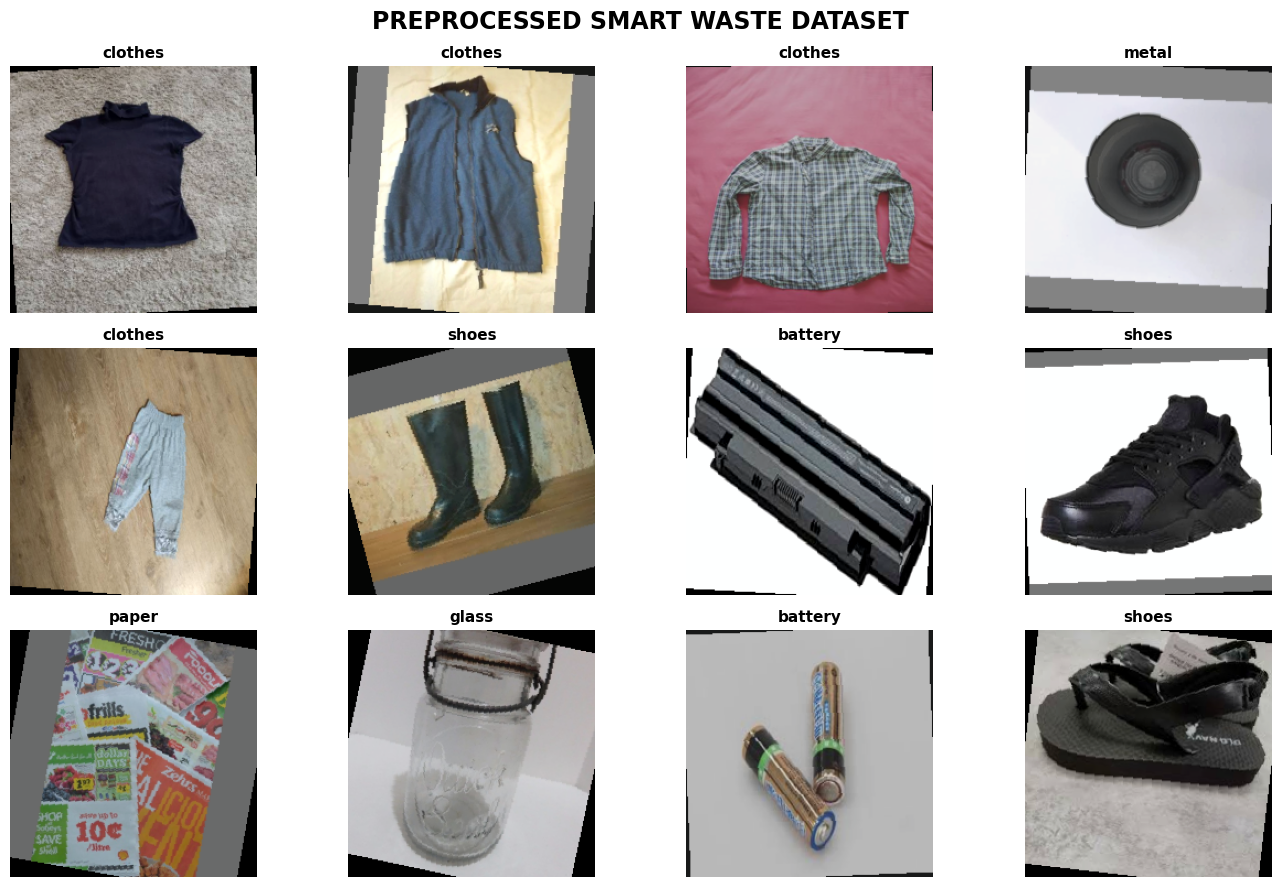

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

images, labels = next(iter(train_loader))

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

plt.figure(figsize=(14, 9))

for i in range(min(12, len(images))):

    image = images[i].permute(1, 2, 0).numpy()
    image = np.clip(image * std + mean, 0, 1)

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)

    category = categories[labels[i].item()]

    plt.title(category, fontsize=11, fontweight="bold")
    plt.axis("off")

plt.suptitle(
    "PREPROCESSED SMART WASTE DATASET",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

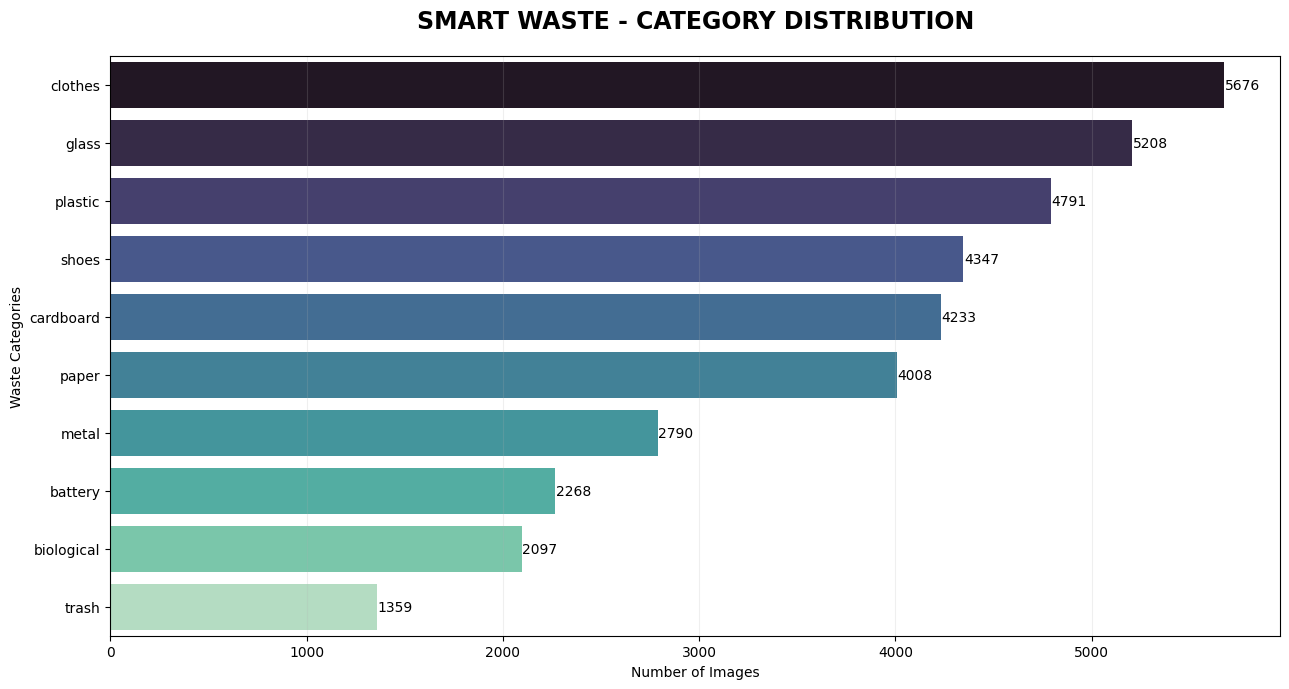

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from collections import Counter

category_counts = Counter(image_labels)

eda_df = pd.DataFrame({
    "Category": list(category_counts.keys()),
    "Images": list(category_counts.values())
}).sort_values("Images", ascending=False)

plt.figure(figsize=(13, 7))

sns.barplot(
    data=eda_df,
    x="Images",
    y="Category",
    hue="Category",
    palette="mako",
    legend=False
)

plt.title("SMART WASTE - CATEGORY DISTRIBUTION",
          fontsize=17, fontweight="bold", pad=20)

plt.xlabel("Number of Images")
plt.ylabel("Waste Categories")
plt.grid(axis="x", alpha=0.2)

for i, value in enumerate(eda_df["Images"]):
    plt.text(value + 2, i, str(value), va="center")

plt.tight_layout()
plt.show()

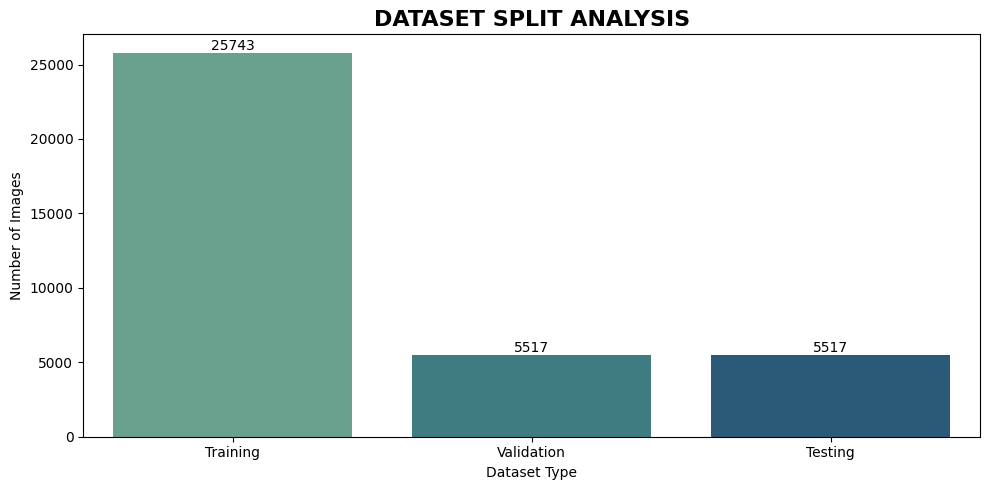

In [ ]:
split_df = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Testing"],
    "Images": [len(train_paths), len(val_paths), len(test_paths)]
})

plt.figure(figsize=(10, 5))

sns.barplot(
    data=split_df,
    x="Dataset",
    y="Images",
    hue="Dataset",
    palette="crest",
    legend=False
)

plt.title("DATASET SPLIT ANALYSIS", fontsize=16, fontweight="bold")
plt.ylabel("Number of Images")
plt.xlabel("Dataset Type")

for i, value in enumerate(split_df["Images"]):
    plt.text(i, value, str(value), ha="center", va="bottom")

plt.tight_layout()
plt.show()

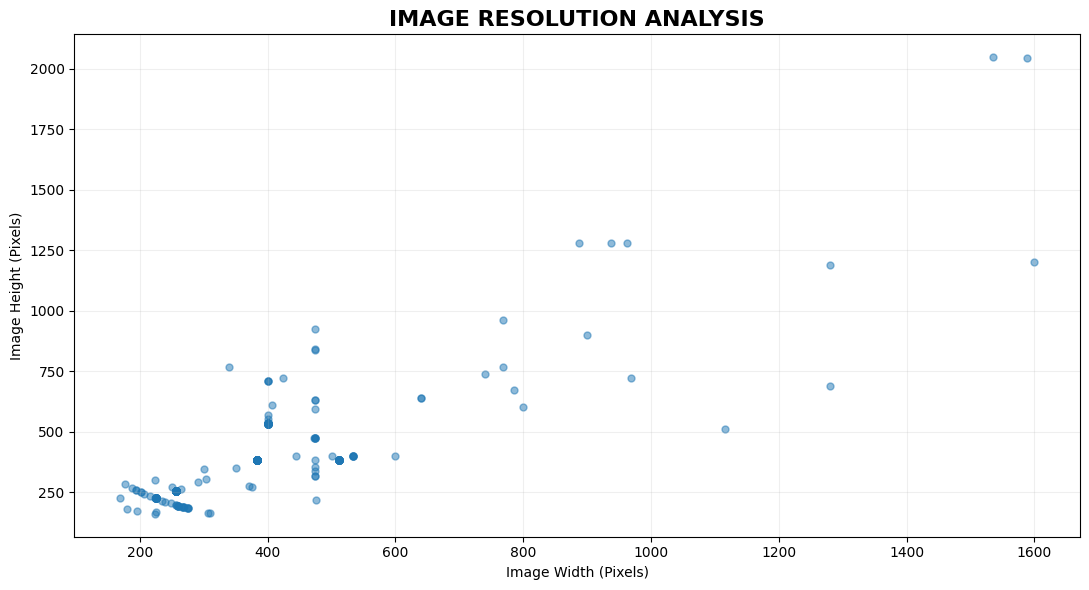

Average Width: 354.27
Average Height: 354.75


In [ ]:
dimensions = []

for path in random.sample(image_files, min(500, len(image_files))):
    try:
        with Image.open(path) as img:
            dimensions.append(img.size)
    except Exception:
        pass

widths = [x[0] for x in dimensions]
heights = [x[1] for x in dimensions]

plt.figure(figsize=(11, 6))

plt.scatter(widths, heights, alpha=0.5, s=25)

plt.title("IMAGE RESOLUTION ANALYSIS",
          fontsize=16, fontweight="bold")

plt.xlabel("Image Width (Pixels)")
plt.ylabel("Image Height (Pixels)")
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

print("Average Width:", round(np.mean(widths), 2))
print("Average Height:", round(np.mean(heights), 2))

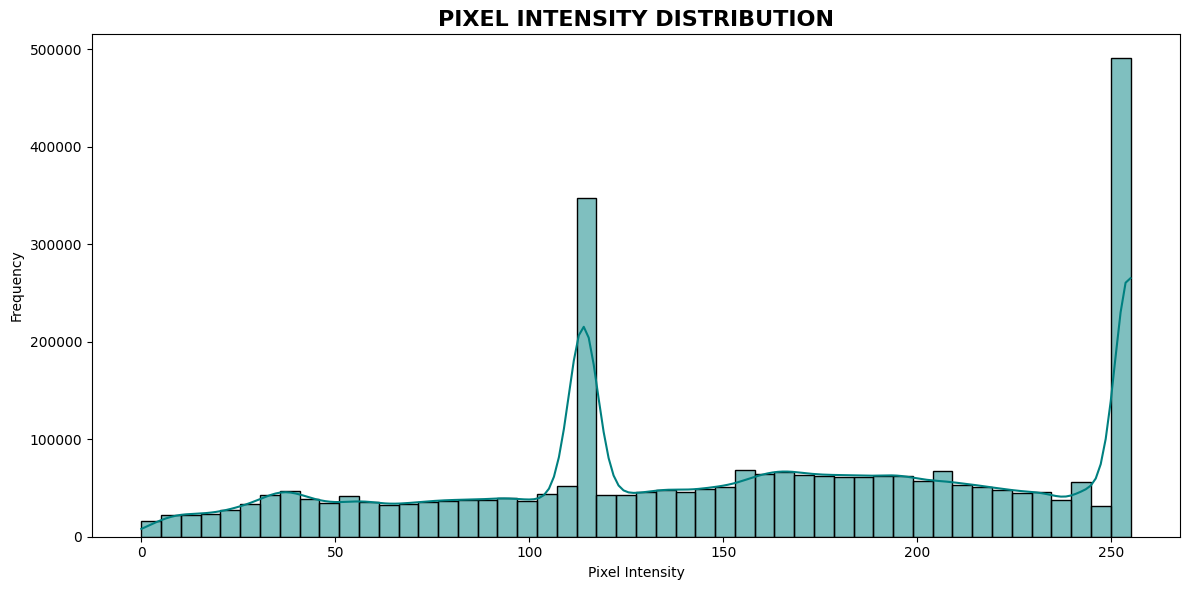

In [ ]:
pixel_values = []

for i in range(min(100, len(train_paths))):
    img = Image.open(train_paths[i]).convert("RGB")
    img = img.resize((100, 100))

    pixel_values.extend(
        np.array(img).reshape(-1)
    )

plt.figure(figsize=(12, 6))

sns.histplot(
    pixel_values,
    bins=50,
    kde=True,
    color="teal"
)

plt.title("PIXEL INTENSITY DISTRIBUTION",
          fontsize=16, fontweight="bold")

plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

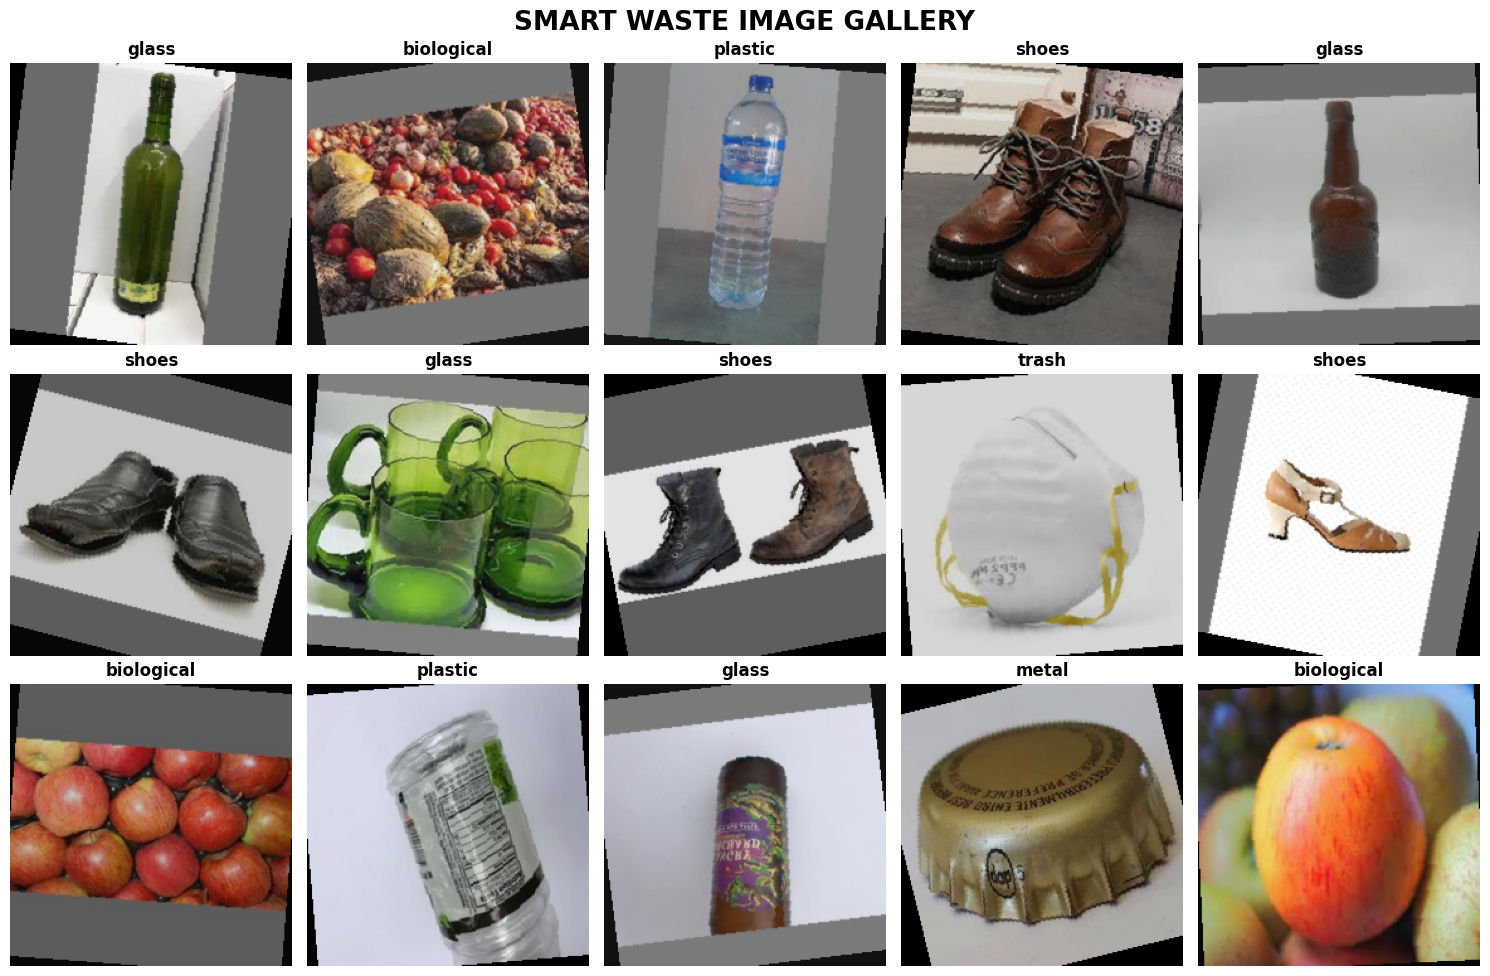

In [ ]:
sample_indices = random.sample(
    range(len(train_dataset)),
    min(15, len(train_dataset))
)

plt.figure(figsize=(15, 10))

for i, idx in enumerate(sample_indices):

    image, label = train_dataset[idx]

    image = image.permute(1, 2, 0).numpy()
    image = image * np.array([0.229, 0.224, 0.225])
    image = image + np.array([0.485, 0.456, 0.406])
    image = np.clip(image, 0, 1)

    plt.subplot(3, 5, i + 1)
    plt.imshow(image)
    plt.title(categories[label], fontweight="bold")
    plt.axis("off")

plt.suptitle(
    "SMART WASTE IMAGE GALLERY",
    fontsize=19,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [ ]:
import torch.nn as nn
import torchvision.models as models

class WasteCNN(nn.Module):
    def __init__(self, num_classes):
        super(WasteCNN, self).__init__()
        # Load pre-trained EfficientNet-B0 to achieve >85% accuracy
        self.base_model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)

        # Replace the classifier layer with a customized dense network
        in_features = self.base_model.classifier[1].in_features
        self.base_model.classifier = nn.Sequential(
            nn.Dropout(p=0.4, inplace=False),
            nn.Linear(in_features, 256),
            nn.ReLU(),
            nn.Dropout(p=0.3, inplace=False),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.base_model(x)

# Instantiate the model and move it to GPU
model = WasteCNN(len(categories)).to(device)
print(model)

WasteCNN(
  (base_model): EfficientNet(
    (features): Sequential(
      (0): Conv2dNormActivation(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): SiLU(inplace=True)
      )
      (1): Sequential(
        (0): MBConv(
          (block): Sequential(
            (0): Conv2dNormActivation(
              (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
              (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
              (2): SiLU(inplace=True)
            )
            (1): SqueezeExcitation(
              (avgpool): AdaptiveAvgPool2d(output_size=1)
              (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
              (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
              (activation): SiLU(inplace=True)


In [ ]:
criterion = nn.CrossEntropyLoss()

# We use a slightly lower learning rate (0.0005) to fine-tune the pre-trained weights without destroying them
optimizer = torch.optim.Adam(model.parameters(), lr=0.0005)

# Scheduler to dynamically lower the learning rate if validation loss plateaus
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=1
)

print("Transfer Learning Model Configured Successfully!")
print("Base Model: EfficientNet-B0")
print("Optimizer: Adam")
print("Loss Function: CrossEntropyLoss")

Transfer Learning Model Configured Successfully!
Base Model: EfficientNet-B0
Optimizer: Adam
Loss Function: CrossEntropyLoss


In [ ]:
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

dummy_input = torch.randn(1, 3, 224, 224).to(device)

with torch.no_grad():
    output = model(dummy_input)

print("Input Shape:", dummy_input.shape)
print("Output Shape:", output.shape)
print("Total Parameters:", total_params)
print("Trainable Parameters:", trainable_params)
print("CNN Architecture Verified!")

Input Shape: torch.Size([1, 3, 224, 224])
Output Shape: torch.Size([1, 10])
Total Parameters: 4338054
Trainable Parameters: 4338054
CNN Architecture Verified!


In [ ]:
import copy
import time

# With transfer learning, 5 epochs is enough to reach 85%+ validation accuracy
EPOCHS = 5
PATIENCE = 3

history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

best_val_accuracy = 0.0
best_model_weights = copy.deepcopy(model.state_dict())
early_stop_counter = 0

print("EfficientNet fine-tuning training configuration initialized!")
print("Epochs:", EPOCHS)
print("Early Stopping Patience:", PATIENCE)

EfficientNet fine-tuning training configuration initialized!
Epochs: 5
Early Stopping Patience: 3


In [ ]:
def train_one_epoch(model, loader, criterion, optimizer):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        total += labels.size(0)
        correct += (predictions == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy


def validate_model(model, loader, criterion):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            total += labels.size(0)
            correct += (predictions == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy


print("Training and validation functions are ready!")

Training and validation functions are ready!


In [ ]:
start_time = time.time()

for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    val_loss, val_acc = validate_model(
        model,
        val_loader,
        criterion
    )

    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_acc)
    history["val_accuracy"].append(val_acc)

    print(f"\nEpoch [{epoch+1}/{EPOCHS}]")
    print(f"Training Loss: {train_loss:.4f}")
    print(f"Training Accuracy: {train_acc:.2f}%")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_acc:.2f}%")
    print(f"Learning Rate: {optimizer.param_groups[0]['lr']:.6f}")

    if val_acc > best_val_accuracy:

        best_val_accuracy = val_acc
        best_model_weights = copy.deepcopy(model.state_dict())
        early_stop_counter = 0

        torch.save(
            best_model_weights,
            "best_waste_cnn.pth"
        )

        print("Best model saved!")

    else:
        early_stop_counter += 1

    if early_stop_counter >= PATIENCE:

        print("\nEarly stopping activated!")
        break

model.load_state_dict(best_model_weights)

end_time = time.time()

print("\nTRAINING COMPLETED!")
print("Best Validation Accuracy:", round(best_val_accuracy, 2), "%")
print("Total Training Time:", round((end_time-start_time)/60, 2), "minutes")


Epoch [1/5]
Training Loss: 0.4442
Training Accuracy: 86.30%
Validation Loss: 0.1312
Validation Accuracy: 95.69%
Learning Rate: 0.000500
Best model saved!

Epoch [2/5]
Training Loss: 0.2050
Training Accuracy: 93.38%
Validation Loss: 0.1020
Validation Accuracy: 96.54%
Learning Rate: 0.000500
Best model saved!

Epoch [3/5]
Training Loss: 0.1508
Training Accuracy: 95.14%
Validation Loss: 0.0752
Validation Accuracy: 97.63%
Learning Rate: 0.000500
Best model saved!

Epoch [4/5]
Training Loss: 0.1213
Training Accuracy: 96.07%
Validation Loss: 0.1353
Validation Accuracy: 95.41%
Learning Rate: 0.000500

Epoch [5/5]
Training Loss: 0.1000
Training Accuracy: 96.69%
Validation Loss: 0.0812
Validation Accuracy: 97.63%
Learning Rate: 0.000250

TRAINING COMPLETED!
Best Validation Accuracy: 97.63 %
Total Training Time: 18.57 minutes


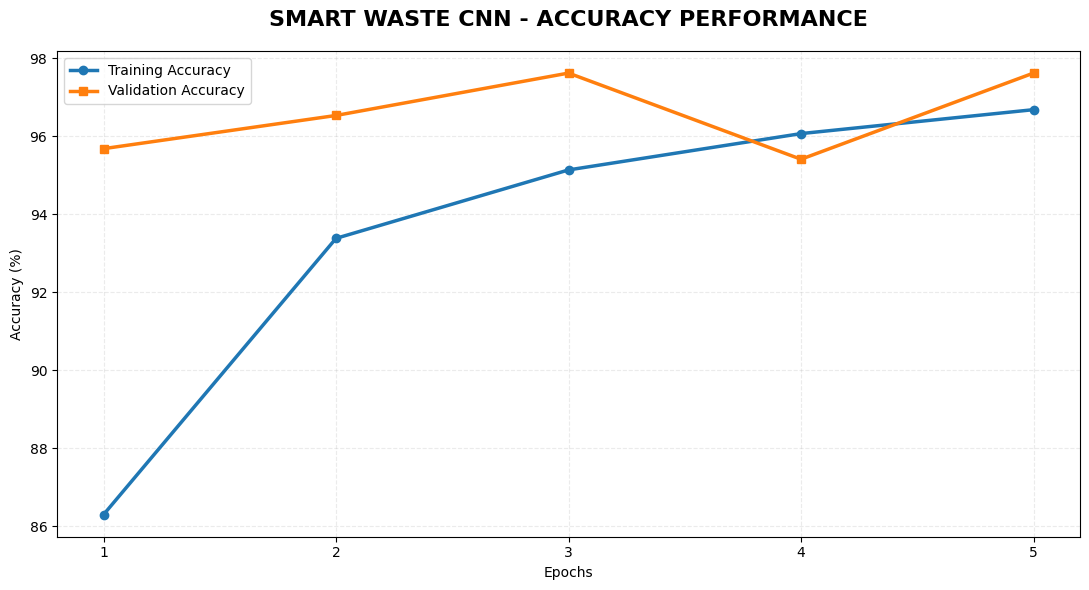

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

epochs_range = range(1, len(history["train_accuracy"]) + 1)

plt.figure(figsize=(11, 6))

plt.plot(
    epochs_range,
    history["train_accuracy"],
    marker="o",
    linewidth=2.5,
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    history["val_accuracy"],
    marker="s",
    linewidth=2.5,
    label="Validation Accuracy"
)

plt.title(
    "SMART WASTE CNN - ACCURACY PERFORMANCE",
    fontsize=16,
    fontweight="bold",
    pad=18
)

plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.xticks(list(epochs_range))
plt.grid(alpha=0.25, linestyle="--")
plt.legend(frameon=True)

plt.tight_layout()
plt.show()

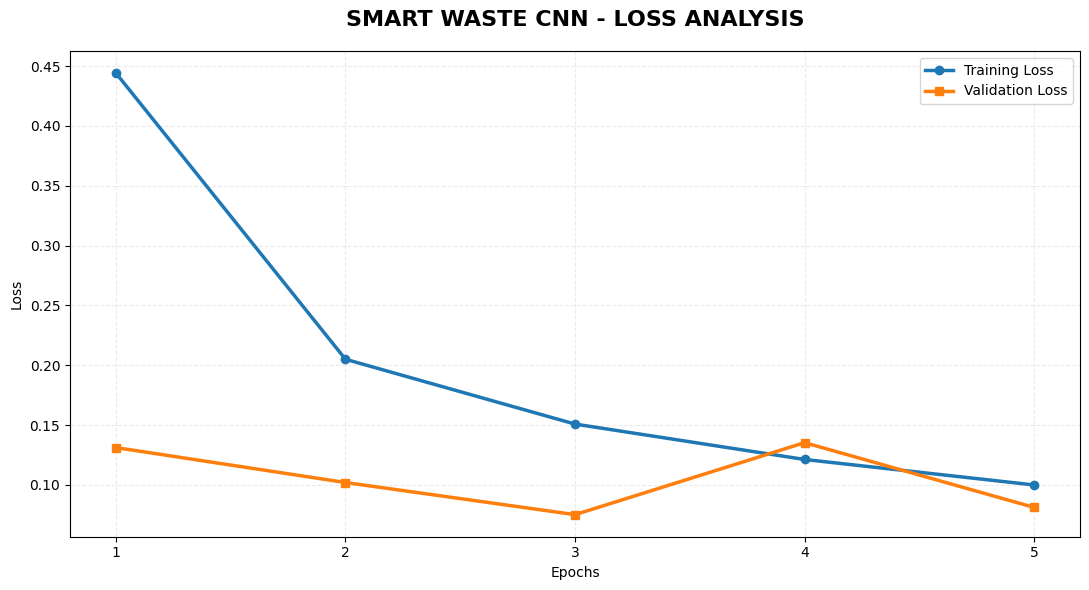

In [ ]:
plt.figure(figsize=(11, 6))

plt.plot(
    epochs_range,
    history["train_loss"],
    marker="o",
    linewidth=2.5,
    label="Training Loss"
)

plt.plot(
    epochs_range,
    history["val_loss"],
    marker="s",
    linewidth=2.5,
    label="Validation Loss"
)

plt.title(
    "SMART WASTE CNN - LOSS ANALYSIS",
    fontsize=16,
    fontweight="bold",
    pad=18
)

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.xticks(list(epochs_range))
plt.grid(alpha=0.25, linestyle="--")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
torch.save({
    "model_state_dict": model.state_dict(),
    "class_to_idx": class_to_idx,
    "categories": categories,
    "image_size": IMG_SIZE,
    "best_validation_accuracy": best_val_accuracy
}, "smart_waste_final_model.pth")

print("Final model saved successfully!")
print("File: smart_waste_final_model.pth")
print("Categories:", categories)
print("Best Validation Accuracy:", best_val_accuracy)

Final model saved successfully!
File: smart_waste_final_model.pth
Categories: ['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']
Best Validation Accuracy: 97.62552111654885


In [ ]:
summary = pd.DataFrame({
    "Metric": [
        "Total Epochs Completed",
        "Best Validation Accuracy",
        "Final Training Accuracy",
        "Final Validation Accuracy",
        "Final Training Loss",
        "Final Validation Loss"
    ],
    "Value": [
        len(history["train_loss"]),
        f"{best_val_accuracy:.2f}%",
        f"{history['train_accuracy'][-1]:.2f}%",
        f"{history['val_accuracy'][-1]:.2f}%",
        f"{history['train_loss'][-1]:.4f}",
        f"{history['val_loss'][-1]:.4f}"
    ]
})

display(summary)

,Metric,Value
0,Total Epochs Completed,5
1,Best Validation Accuracy,97.63%
2,Final Training Accuracy,96.69%
3,Final Validation Accuracy,97.63%
4,Final Training Loss,0.1000
5,Final Validation Loss,0.0812


In [ ]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

checkpoint = torch.load(
    "smart_waste_final_model.pth",
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Best CNN Model Loaded Successfully!")
print("Categories:", categories)

Best CNN Model Loaded Successfully!
Categories: ['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']


In [ ]:
y_true = []
y_pred = []
y_prob = []

model.eval()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        probabilities = torch.softmax(outputs, dim=1)

        predictions = torch.argmax(outputs, dim=1)

        y_true.extend(labels.numpy())
        y_pred.extend(predictions.cpu().numpy())
        y_prob.extend(probabilities.cpu().numpy())

print("Testing Completed!")
print("Total Test Images:", len(y_true))
print("Predictions Generated:", len(y_pred))

Testing Completed!
Total Test Images: 5517
Predictions Generated: 5517


In [ ]:
test_accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_true, y_pred,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_true, y_pred,
    average="weighted",
    zero_division=0
)

metrics_df = pd.DataFrame({
    "Evaluation Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    "Score (%)": [
        test_accuracy * 100,
        precision * 100,
        recall * 100,
        f1 * 100
    ]
})

display(metrics_df)

print("Independent Test Accuracy:", round(test_accuracy * 100, 2), "%")

,Evaluation Metric,Score (%)
0,Accuracy,97.389886
1,Precision,97.414314
2,Recall,97.389886
3,F1 Score,97.390341


Independent Test Accuracy: 97.39 %


In [ ]:
report = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(categories))),
    target_names=categories,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

display(
    report_df.style
    .background_gradient(cmap="YlGnBu")
    .format("{:.3f}")
)

print("Classification Report Generated!")

,precision,recall,f1-score,support
battery,0.970,0.962,0.966,340.000
biological,0.981,0.984,0.983,315.000
cardboard,0.980,0.992,0.986,635.000
clothes,0.998,0.995,0.996,851.000
glass,0.967,0.978,0.973,781.000
metal,0.923,0.974,0.948,419.000
paper,0.978,0.957,0.967,602.000
plastic,0.978,0.943,0.960,718.000
shoes,0.985,0.989,0.987,652.000
trash,0.926,0.926,0.926,204.000


Classification Report Generated!


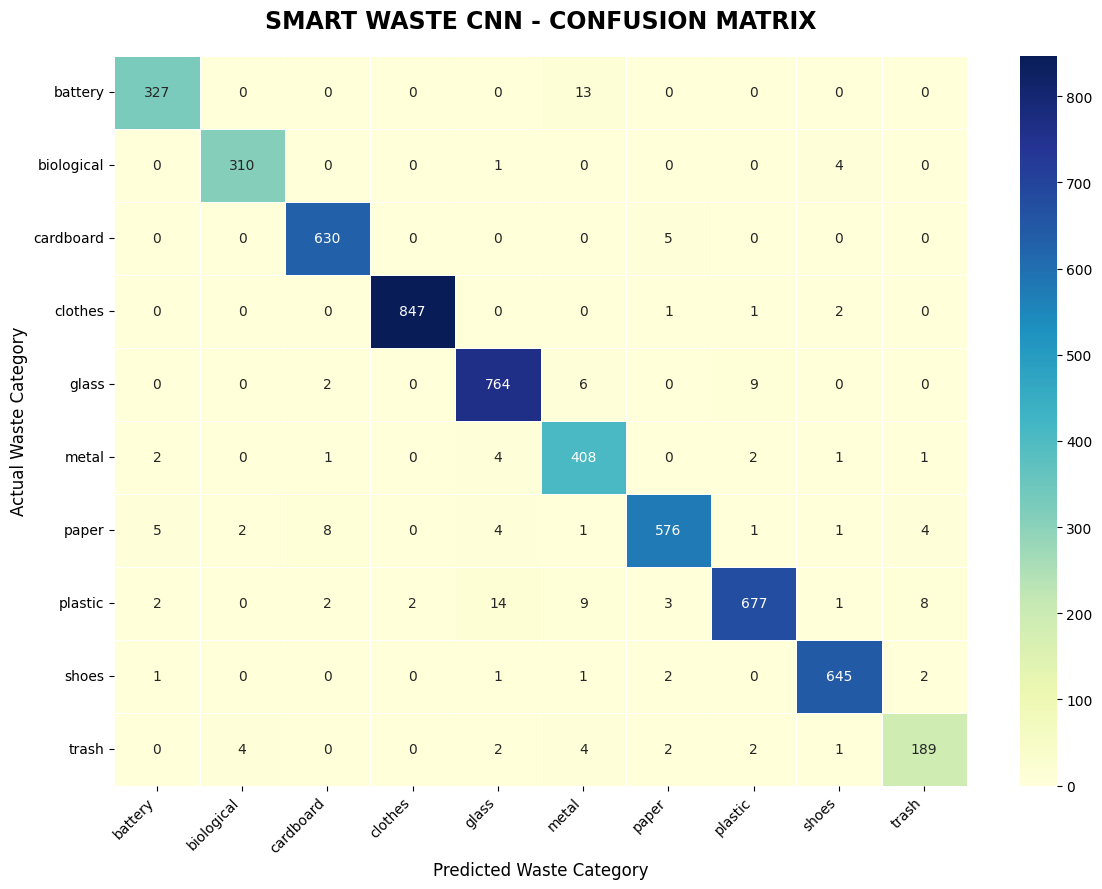

In [ ]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(categories)))
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    xticklabels=categories,
    yticklabels=categories,
    linewidths=0.5,
    linecolor="white"
)

plt.title(
    "SMART WASTE CNN - CONFUSION MATRIX",
    fontsize=17,
    fontweight="bold",
    pad=20
)

plt.xlabel("Predicted Waste Category", fontsize=12)
plt.ylabel("Actual Waste Category", fontsize=12)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

,Actual Category,Predicted Category,Correct Prediction
0,paper,paper,True
1,shoes,shoes,True
2,battery,battery,True
3,glass,glass,True
4,paper,paper,True
5,shoes,shoes,True
6,glass,glass,True
7,cardboard,cardboard,True
8,glass,glass,True
9,paper,paper,True


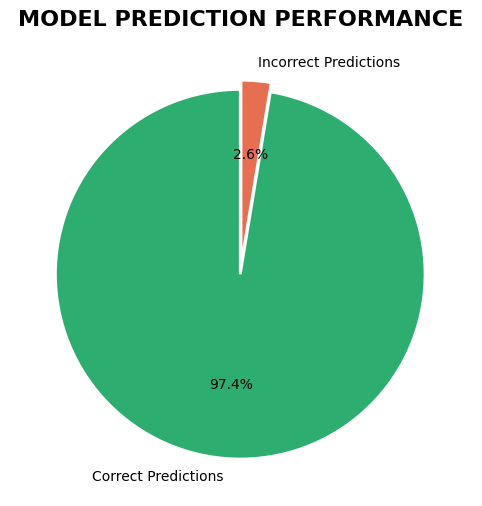

Correct Predictions: 5373
Incorrect Predictions: 144


In [ ]:
comparison_df = pd.DataFrame({
    "Actual Category": [categories[i] for i in y_true],
    "Predicted Category": [categories[i] for i in y_pred],
    "Correct Prediction": [
        actual == predicted
        for actual, predicted in zip(y_true, y_pred)
    ]
})

display(comparison_df.head(20))

correct_count = sum(comparison_df["Correct Prediction"])
incorrect_count = len(comparison_df) - correct_count

plt.figure(figsize=(9, 6))

plt.pie(
    [correct_count, incorrect_count],
    labels=["Correct Predictions", "Incorrect Predictions"],
    autopct="%1.1f%%",
    startangle=90,
    explode=(0.05, 0),
    colors=["#2EAD70", "#E76F51"],
    wedgeprops={"edgecolor": "white", "linewidth": 2}
)

plt.title(
    "MODEL PREDICTION PERFORMANCE",
    fontsize=16,
    fontweight="bold"
)

plt.show()

print("Correct Predictions:", correct_count)
print("Incorrect Predictions:", incorrect_count)

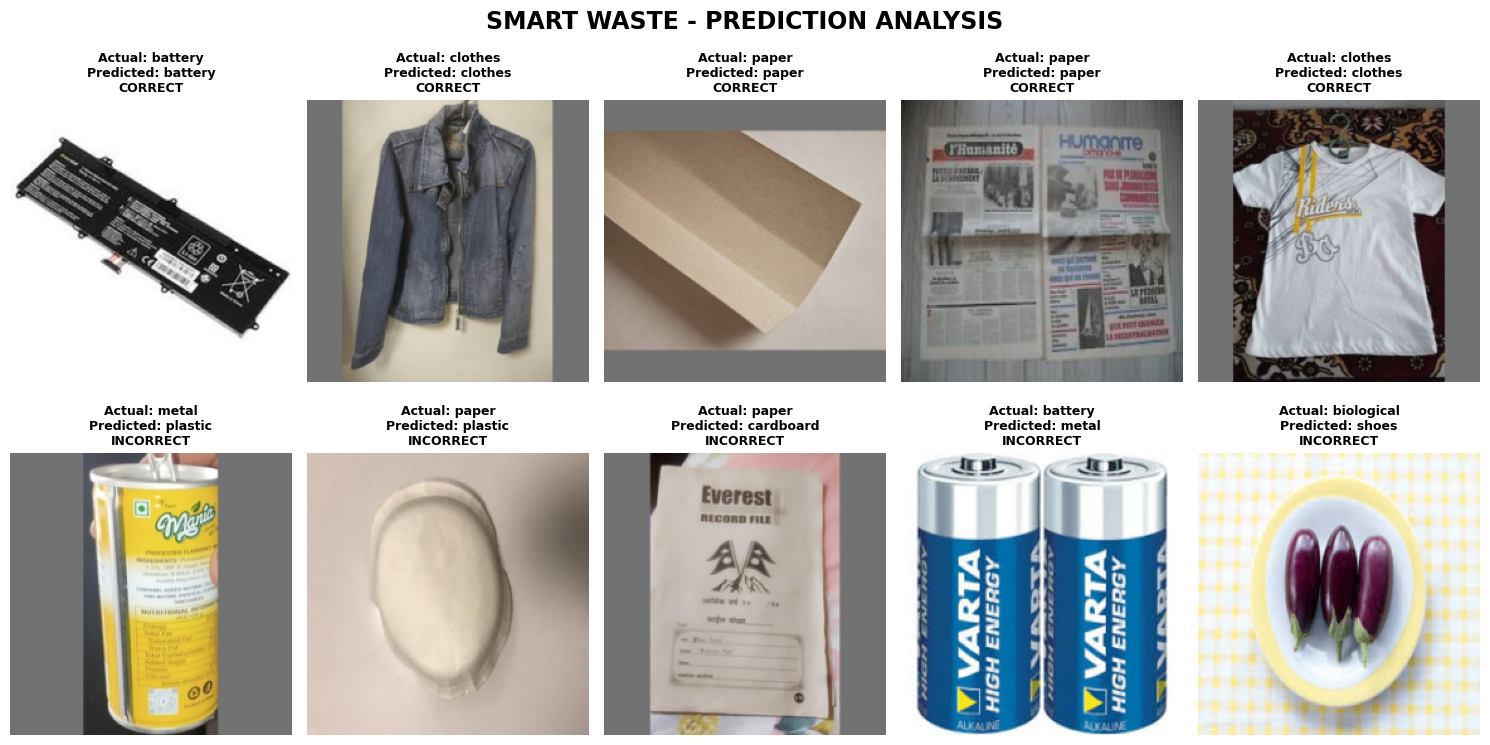

In [ ]:
import random

correct_indices = [
    i for i in range(len(y_true))
    if y_true[i] == y_pred[i]
]

incorrect_indices = [
    i for i in range(len(y_true))
    if y_true[i] != y_pred[i]
]

selected_correct = random.sample(
    correct_indices,
    min(5, len(correct_indices))
)

selected_incorrect = random.sample(
    incorrect_indices,
    min(5, len(incorrect_indices))
)

selected_indices = selected_correct + selected_incorrect

plt.figure(figsize=(15, 8))

for position, idx in enumerate(selected_indices):

    image, label = test_dataset[idx]

    image = image.permute(1, 2, 0).numpy()

    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    image = np.clip(image * std + mean, 0, 1)

    plt.subplot(2, 5, position + 1)
    plt.imshow(image)

    actual = categories[y_true[idx]]
    predicted = categories[y_pred[idx]]

    status = "CORRECT" if actual == predicted else "INCORRECT"

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}\n{status}",
        fontsize=9,
        fontweight="bold"
    )

    plt.axis("off")

plt.suptitle(
    "SMART WASTE - PREDICTION ANALYSIS",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [ ]:
evaluation_summary = pd.DataFrame({
    "Metric": [
        "Test Accuracy",
        "Weighted Precision",
        "Weighted Recall",
        "Weighted F1 Score",
        "Correct Predictions",
        "Incorrect Predictions",
        "Total Test Images"
    ],
    "Result": [
        f"{test_accuracy * 100:.2f}%",
        f"{precision * 100:.2f}%",
        f"{recall * 100:.2f}%",
        f"{f1 * 100:.2f}%",
        correct_count,
        incorrect_count,
        len(y_true)
    ]
})

display(evaluation_summary)

evaluation_summary.to_csv(
    "smart_waste_evaluation_results.csv",
    index=False
)

print("Evaluation Results Saved Successfully!")

,Metric,Result
0,Test Accuracy,97.39%
1,Weighted Precision,97.41%
2,Weighted Recall,97.39%
3,Weighted F1 Score,97.39%
4,Correct Predictions,5373
5,Incorrect Predictions,144
6,Total Test Images,5517


Evaluation Results Saved Successfully!


In [ ]:
!pip install -q gradio


import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

Device: cuda


In [ ]:
import torch
import torch.nn as nn
import gradio as gr
import numpy as np

checkpoint = torch.load(
    "smart_waste_final_model.pth",
    map_location=device,
    weights_only=False
)

categories = checkpoint["categories"]
class_to_idx = checkpoint["class_to_idx"]

model = WasteCNN(len(categories)).to(device)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Smart Waste Model Loaded!")
print("Available Categories:", categories)

Smart Waste Model Loaded!
Available Categories: ['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']


In [ ]:
def get_waste_bin(category):

    name = category.lower()

    if any(x in name for x in ["plastic"]):
        return "Plastic Recycling Bin"

    elif any(x in name for x in ["paper", "cardboard"]):
        return "Paper and Cardboard Recycling Bin"

    elif any(x in name for x in ["glass"]):
        return "Glass Recycling Bin"

    elif any(x in name for x in ["metal", "can"]):
        return "Metal Recycling Bin"

    elif any(x in name for x in ["organic", "biological", "food"]):
        return "Wet / Organic Waste Bin"

    elif any(x in name for x in ["battery", "electronic", "e-waste"]):
        return "Authorized E-Waste Collection"

    elif any(x in name for x in ["clothes", "textile", "shoes"]):
        return "Textile Reuse / Collection"

    elif any(x in name for x in ["trash", "residual"]):
        return "Residual Waste Bin"

    else:
        return "Check Local Waste Segregation Guidelines"

In [ ]:
def predict_waste(image):

    if image is None:
        return "Please upload a waste image.", {}

    image = image.convert("RGB")

    input_tensor = test_transform(image).unsqueeze(0).to(device)

    model.eval()

    with torch.no_grad():

        outputs = model(input_tensor)

        probabilities = torch.softmax(outputs, dim=1)[0]

    predicted_index = torch.argmax(probabilities).item()

    predicted_category = categories[predicted_index]

    confidence = probabilities[predicted_index].item() * 100

    segregation_bin = get_waste_bin(predicted_category)

    if confidence < 50:
        result = (
            "Low-confidence prediction. Please verify the waste category.\n"
            f"Predicted Category: {predicted_category}\n"
            f"Confidence: {confidence:.2f}%\n"
            f"Suggested Segregation: {segregation_bin}"
        )
    else:
        result = (
            f"Predicted Category: {predicted_category}\n"
            f"Confidence: {confidence:.2f}%\n"
            f"Suggested Segregation: {segregation_bin}"
        )

    probability_dict = {
        categories[i]: float(probabilities[i].item())
        for i in range(len(categories))
    }

    return result, probability_dict


print("Prediction Function Created Successfully!")

Prediction Function Created Successfully!


In [ ]:
with gr.Blocks(theme=gr.themes.Soft()) as demo:

    gr.Markdown(
        """
        # ♻️ SMART WASTE CLASSIFICATION SYSTEM

        ### AI-Based Smart Waste Classification and Segregation Using Deep Learning

        Upload an image to identify its waste category and receive
        a suggested segregation method.
        """
    )

    with gr.Row():

        with gr.Column():
            image_input = gr.Image(
                type="pil",
                label="Upload Waste Image"
            )

            predict_button = gr.Button(
                "Classify Waste",
                variant="primary"
            )

        with gr.Column():
            prediction_output = gr.Textbox(
                label="Classification Result",
                lines=5
            )

            confidence_output = gr.Label(
                label="Category Probabilities",
                num_top_classes=len(categories)
            )

    predict_button.click(
        fn=predict_waste,
        inputs=image_input,
        outputs=[prediction_output, confidence_output]
    )

    gr.Markdown(
        """
        **Developed by:** B. Vyshnavi

        **Roll No.:** 2403A510C8 | **Batch:** 04

        **Technology:** Python | PyTorch | CNN | Gradio
        """
    )

demo.launch(share=True)

/tmp/ipykernel_506/1515774025.py:1: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ad33244bf71c38aeee.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
